In [1]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import geopandas as gpd
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "Libertinus Serif",
    "font.size": CORPS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

NACHTBLAUW, STEENGRIJS = KLEUR_NACHT, "#96999B"
PALET = ["#0067B9", "#FF9527", "#00859B", "#007044", "#E100A3", "#9569BE", "#CC982F"]

SEED = 42
NACHTCATS = ["nacht", "avondschemering", "ochtendschemering"]
SLEUTEL = ["archive_file", "Incident Number"]

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [2]:
FIG = Path("../../fig/H8"); FIG.mkdir(parents=True, exist_ok=True)

def bewaar(fig, naam):
    for ext in ("png",):
        pas_breedte_aan(fig, tight=True)
        fig.savefig(FIG / f"{naam}.{ext}", dpi=300, bbox_inches="tight")

In [3]:
df = pd.read_excel("../../data/H8/geluidsoverlast_w3_nacht_allepersonen.xlsx")
df_gb = df.drop_duplicates(subset=SLEUTEL)

In [4]:
geluidspraktijk_kolommen = ['arguing', 'doorbell ringing', 'playing inn music', 'scolding', 'singing', 'yelling']

In [5]:
heeft_praktijk = (df_gb[geluidspraktijk_kolommen].sum(axis=1) > 0).sum()
print(heeft_praktijk)

479


In [6]:
# verschilt de verdeling van 'geen specifieke praktijk' over tijd/wijk/hisclass?
df_gb['heeft_praktijk'] = df_gb[geluidspraktijk_kolommen].sum(axis=1) > 0
print(pd.crosstab(df_gb['heeft_praktijk'], df_gb['year'], normalize='columns'))

year            1877.0    1878.0    1880.0    1881.0    1882.0    1883.0  \
heeft_praktijk                                                             
False           0.5625  0.322581  0.298507  0.291667  0.480769  0.448276   
True            0.4375  0.677419  0.701493  0.708333  0.519231  0.551724   

year             1884.0    1885.0    1886.0    1887.0  ...  1930.0  1931.0  \
heeft_praktijk                                         ...                   
False           0.27027  0.448276  0.487805  0.346939  ...   0.375     0.2   
True            0.72973  0.551724  0.512195  0.653061  ...   0.625     0.8   

year              1932.0    1933.0  1934.0    1935.0  1936.0    1937.0  \
heeft_praktijk                                                           
False           0.571429  0.333333    0.75  0.636364     0.6  0.230769   
True            0.428571  0.666667    0.25  0.363636     0.4  0.769231   

year              1938.0  1939.0  
heeft_praktijk                    
False          

/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_44982/3772544435.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_gb['heeft_praktijk'] = df_gb[geluidspraktijk_kolommen].sum(axis=1) > 0


In [7]:
counts = df_gb[df_gb["E_LOC_gis1898"] != "unknown"].groupby("E_LOC_gis1898").size().reset_index(name="geluidsoverlast_ls")
top10 = counts.nlargest(20, "geluidsoverlast_ls")["E_LOC_gis1898"].tolist()
top10

['OUDEVAARTPLAATS',
 'GROENPLAATS',
 'LOMBAARDVEST',
 'MEIRPLAATS',
 'BONTEMANTELSTRAAT',
 'ST.-JORISVEST',
 'LANGE NIEUW STRAAT',
 'MEIR',
 'SCHUTTERSHOFSTRAAT',
 'KUNSTLEI',
 'BEURS-ZUID',
 'KELDERSTRAAT',
 'LEOPOLDSTRAAT',
 'MECHELSEPLEIN',
 'EVERDIJSTRAAT',
 'KAMMENSTRAAT',
 'LEYSSTRAAT',
 'LOMBARDENVEST',
 'MEIRBRUG',
 'MEISTRAAT']

In [8]:
 #filter op top 10
df_top10 = df_gb[df_gb["E_LOC_gis1898"].isin(top10)]
df_top10


,archive_file,year,district,Person ID,Incident Number,Page Number,E_DATE,E_TIME,E_LOC,P_FIRSTNAME,...,scolding,silence,singing,traffic noise,whistling,yelling,geluidsoverlast_y,geluidsoverlast,bronbestand,heeft_praktijk
3,MA#17881,1920.0,3.0,946.0,613.0,158.0,NaN,nacht;125 ure;middd,groenplast;Nioolstraat,Henri,...,1.0,NaN,NaN,NaN,NaN,1.0,NaN,stoorde; nachtlawooy,MA#17881_with_text.xlsx,True
4,731#1595,1880.0,3.0,1099.0,809.0,186.0,25 op 26,11 / 4 uur snachts,oude vaart plaats;bonte mantel straat,hendricus,...,NaN,NaN,1.0,NaN,NaN,1.0,NaN,stoorde; luidkeels,731#1595_with_text.xlsx,True
10,731#1611,1888.0,3.0,31.0,26.0,8.0,21 Mart 81,nacht;4 uren,Leys st .,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,luidkeels,731#1611_with_text.xlsx,False
13,731#1611,1888.0,3.0,3220.0,2577.0,490.0,NaN,nacht;1 1 / 2 uren;512 uur s morgends,n 14;KunstLei,Jan,...,NaN,NaN,1.0,NaN,NaN,1.0,NaN,schreeuwen,731#1611_with_text.xlsx,True
20,731#1611,1888.0,3.0,42.0,34.0,10.0,NaN,nacht;1 1 / 2 uur,Meir,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,nachtlanwijd,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1799,731#1613,1889.0,3.0,2619.0,2750.0,535.0,NaN,"10 , 45 ' s avonds",beurs,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,schreeuwen,731#1613_with_text.xlsx,False
1800,731#1611,1888.0,3.0,3460.0,2793.0,530.0,NaN,avond;1150 ure,27 der Bantemantel strat;Boutemantel straat,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,nachtrust; stoorde,NaN,NaN,True
1809,731#1613,1889.0,3.0,2819.0,2987.0,579.0,20 - 12 - 89,nacht;12 1 / 4 uur,schuttershof st,J . B,...,0.0,0.0,0.0,0.0,0.0,1.0,nachtrust; luidkeels,NaN,NaN,True
1814,731#1614,1890.0,3.0,2732.0,3071.0,580.0,NaN,nacht;220 ure,Kemstlei,Catherina,...,0.0,0.0,0.0,0.0,0.0,0.0,lawgjd,NaN,NaN,False


In [9]:
# som van elke praktijk per straat
result = df_top10.groupby("E_LOC_gis1898")[geluidspraktijk_kolommen].sum()
# meest voorkomende praktijk per straat
result["meest_voorkomend"] = result.idxmax(axis=1)

print(result)


                    arguing  doorbell ringing  playing inn music  scolding  \
E_LOC_gis1898                                                                
BEURS-ZUID              0.0               0.0                0.0       1.0   
BONTEMANTELSTRAAT       5.0               0.0                1.0       2.0   
EVERDIJSTRAAT           1.0               0.0                0.0       0.0   
GROENPLAATS             4.0               0.0                2.0       2.0   
KAMMENSTRAAT            1.0               1.0                1.0       1.0   
KELDERSTRAAT            1.0               0.0                0.0       2.0   
KUNSTLEI                1.0               0.0                0.0       0.0   
LANGE NIEUW STRAAT      2.0               2.0                1.0       1.0   
LEOPOLDSTRAAT           0.0               2.0                1.0       0.0   
LEYSSTRAAT              0.0               0.0                0.0       0.0   
LOMBAARDVEST            2.0               1.0                0.0

In [10]:
result = df_gb[df_gb["E_LOC_gis1898"] != "unknown"].groupby("E_LOC_gis1898")[geluidspraktijk_kolommen].sum().reset_index()
result.to_excel("../../tab/H8/geluidspraktijken_per_straat.xlsx", index=False)

Paar                                     ρ         p
-------------------------------------------------------
  singing – yelling                    0.460    0.0000 ***
  arguing – yelling                    0.380    0.0000 ***
  scolding – yelling                    0.342    0.0000 ***


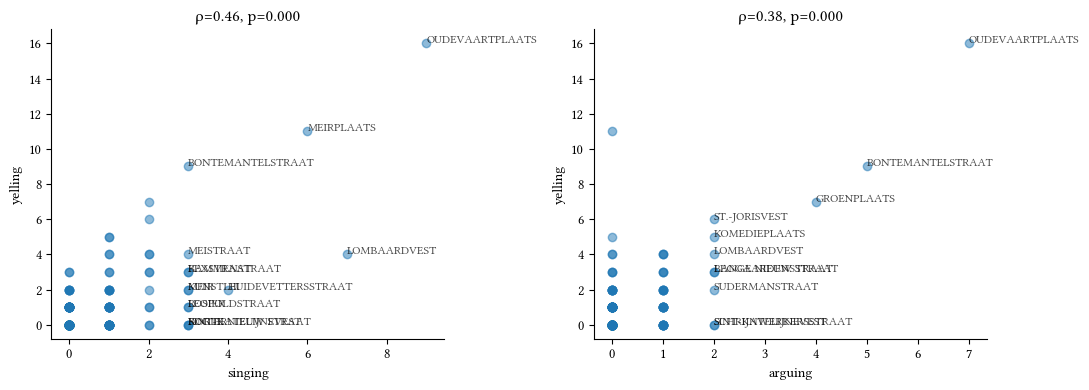

In [11]:
# ── p-waarden bij Spearman ────────────────────────────────────────────────────

pairs = [
    ('singing', 'yelling'),
    ('arguing', 'yelling'),
    ('scolding', 'yelling'),
]

print(f"{'Paar':<35} {'ρ':>6}  {'p':>8}")
print("-" * 55)
for a, b in pairs:
    rho, p = stats.spearmanr(result[a], result[b])
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    print(f"  {a} – {b:<25} {rho:>6.3f}  {p:>8.4f} {sig}")

# ── Scatterplots ──────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (a, b) in zip(axes, [('singing', 'yelling'), ('arguing', 'yelling')]):
    ax.scatter(result[a], result[b], alpha=0.5)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    rho, p = stats.spearmanr(result[a], result[b])
    ax.set_title(f'ρ={rho:.2f}, p={p:.3f}')
    # straatnamen als annotatie voor uitschieters
    threshold = result[a].quantile(0.95)
    for _, row in result[result[a] >= threshold].iterrows():
        ax.annotate(row['E_LOC_gis1898'], (row[a], row[b]),
                    fontsize=CORPS_KLEIN, alpha=0.7)

plt.tight_layout()
plt.show()

In [12]:
pairs = [
    ('singing', 'yelling'),
    ('arguing', 'yelling'),
    ('scolding', 'yelling'),
]

print(f"{'Paar':<35} {'N':>6} {'ρ':>8} {'p':>10}")
print("-" * 65)

results_table = []  # handig als je het later ook wil rapporteren/opslaan

for a, b in pairs:
    sub = result[[a, b]].dropna()          # N = alleen volledige paren
    n = len(sub)
    rho, p = stats.spearmanr(sub[a], sub[b])
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    label = f"{a} – {b}"
    print(f"{label:<35} {n:>6} {rho:>8.3f} {p:>10.4g} {sig}")
    results_table.append({'paar': label, 'N': n, 'rho': rho, 'p': p})

Paar                                     N        ρ          p
-----------------------------------------------------------------
singing – yelling                      157    0.460  1.407e-09 ***
arguing – yelling                      157    0.380  9.248e-07 ***
scolding – yelling                     157    0.342  1.175e-05 ***


In [13]:
print(result.shape)
print(result[['singing','yelling','arguing','scolding']].isna().sum())

(157, 7)
singing     0
yelling     0
arguing     0
scolding    0
dtype: int64


In [14]:
# correlatie tussen praktijken op straatniveau
corr = result[geluidspraktijk_kolommen].corr()
print(corr)


                    arguing  doorbell ringing  playing inn music  scolding  \
arguing            1.000000          0.004761           0.251095  0.598915   
doorbell ringing   0.004761          1.000000           0.056620  0.034312   
playing inn music  0.251095          0.056620           1.000000  0.140339   
scolding           0.598915          0.034312           0.140339  1.000000   
singing            0.498212          0.304742           0.042354  0.455323   
yelling            0.688540          0.166448           0.082707  0.673040   

                    singing   yelling  
arguing            0.498212  0.688540  
doorbell ringing   0.304742  0.166448  
playing inn music  0.042354  0.082707  
scolding           0.455323  0.673040  
singing            1.000000  0.690316  
yelling            0.690316  1.000000  


In [15]:
corr_spearman = result[geluidspraktijk_kolommen].corr(method='spearman')
print(corr_spearman)

                    arguing  doorbell ringing  playing inn music  scolding  \
arguing            1.000000          0.043386           0.246052  0.216839   
doorbell ringing   0.043386          1.000000           0.102119  0.112481   
playing inn music  0.246052          0.102119           1.000000  0.179737   
scolding           0.216839          0.112481           0.179737  1.000000   
singing            0.231585          0.224087           0.121843  0.240676   
yelling            0.379875          0.268551           0.101458  0.341873   

                    singing   yelling  
arguing            0.231585  0.379875  
doorbell ringing   0.224087  0.268551  
playing inn music  0.121843  0.101458  
scolding           0.240676  0.341873  
singing            1.000000  0.459583  
yelling            0.459583  1.000000  


In [16]:
# op eventniveau ipv straatniveau
corr_events = df[geluidspraktijk_kolommen].corr()
corr_events

,arguing,doorbell ringing,playing inn music,scolding,singing,yelling
arguing,1.000000,-0.072262,-0.074276,-0.038549,-0.159650,-0.075241
doorbell ringing,-0.072262,1.000000,-0.035355,-0.030962,-0.058266,-0.074099
playing inn music,-0.074276,-0.035355,1.000000,-0.057060,-0.000556,-0.011389
scolding,-0.038549,-0.030962,-0.057060,1.000000,-0.027997,0.147899
singing,-0.159650,-0.058266,-0.000556,-0.027997,1.000000,-0.041351
yelling,-0.075241,-0.074099,-0.011389,0.147899,-0.041351,1.000000


In [17]:
result["totaal_geb"] = result[geluidspraktijk_kolommen].sum(axis=1)
result.to_excel("../../tab/H8/geluidspraktijken_per_straat.xlsx", index=False)

In [18]:
# 1. definieer periodes
df_gb["periode"] = None
df_gb.loc[df_gb["year"].between(1877, 1892), "periode"] = "vroeg (1877-1892)"
df_gb.loc[df_gb["year"].between(1912, 1939), "periode"] = "laat (1912-1939)"

# filter jaren tussenin weg
df_periodes = df_gb[df_gb["periode"].notna()]

# 2. tel events per periode
counts_periode = df_periodes.groupby("periode").size().reset_index(name="aantal_events")
print(counts_periode)

# 3. praktijken per periode
praktijk_kolommen = ["arguing", "yelling", "singing", "scolding", 
                     "doorbell ringing", "playing inn music", "fighting"]

praktijken_periode = df_periodes.groupby("periode")[praktijk_kolommen].sum()
print(praktijken_periode)

             periode  aantal_events
0   laat (1912-1939)            316
1  vroeg (1877-1892)            502
                   arguing  yelling  singing  scolding  doorbell ringing  \
periode                                                                    
laat (1912-1939)      18.0     74.0     40.0      23.0              15.0   
vroeg (1877-1892)     72.0    143.0    112.0      28.0               8.0   

                   playing inn music  fighting  
periode                                         
laat (1912-1939)                33.0       6.0  
vroeg (1877-1892)                6.0      27.0  


/var/folders/m7/jhz7yh0x2rs_1grxt7m964600000gn/T/ipykernel_44982/2821381351.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_gb["periode"] = None


In [19]:
praktijken_periode.columns

Index(['arguing', 'yelling', 'singing', 'scolding', 'doorbell ringing',
       'playing inn music', 'fighting'],
      dtype='object')

In [20]:
# relatieve frequenties (per 100 events)
praktijken_rel = praktijken_periode.div(counts_periode.set_index("periode")["aantal_events"], axis=0) * 100
print(praktijken_rel.round(2))

                   arguing  yelling  singing  scolding  doorbell ringing  \
periode                                                                    
laat (1912-1939)      5.70    23.42    12.66      7.28              4.75   
vroeg (1877-1892)    14.34    28.49    22.31      5.58              1.59   

                   playing inn music  fighting  
periode                                         
laat (1912-1939)               10.44      1.90  
vroeg (1877-1892)               1.20      5.38  


In [21]:
# 1. split per periode
df_vroeg = df_gb[df_gb["year"].between(1877, 1892)]
df_laat = df_gb[df_gb["year"].between(1912, 1939)]

# 2. aggregeer per straat per periode
def aggregeer(df_periode):
    counts = df_periode[df_periode["E_LOC_gis1898"] != "unknown"] \
        .groupby("E_LOC_gis1898")[praktijk_kolommen + ["year"]].agg(
            {p: "sum" for p in praktijk_kolommen} | {"year": "count"}
        ).reset_index()
    counts = counts.rename(columns={"year": "totaal_events"})
    
    # coördinaten toevoegen
    coords = df_periode.groupby("E_LOC_gis1898").first().reset_index()
    return counts.merge(coords, on="E_LOC_gis1898")

vroeg = aggregeer(df_vroeg)
laat = aggregeer(df_laat)

vroeg.to_excel("../../data/H8/vroeg_1877_1892.xlsx", index=False)
laat.to_excel("../../data/H8/laat_1912_1939.xlsx", index=False)

In [22]:
vroeg.columns

Index(['E_LOC_gis1898', 'arguing_x', 'yelling_x', 'singing_x', 'scolding_x',
       'doorbell ringing_x', 'playing inn music_x', 'fighting_x',
       'totaal_events', 'archive_file', 'year', 'district', 'Person ID',
       'Incident Number', 'Page Number', 'E_DATE', 'E_TIME', 'E_LOC',
       'P_FIRSTNAME', 'P_LASTNAME', 'P_RES', 'P_TITLE', 'P_BIRTHPLACE',
       'P_BIRTHDATE', 'P_AGE', 'P_MARITALSTATUS', 'E_DATE_clean',
       'E_TIME_clean', 'E_TIME_grouped', 'E_LOC_lat', 'E_LOC_long',
       'firstname_firstword', 'gender_inferred', 'firstname_match', 'P_PROF',
       'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass', 'P_AGE_clean',
       'P_BIRTHYEAR', 'P_AGE_categories', 'P_BIRTHPLACE_extra',
       'P_BIRTHPLACE_cleaned', 'P_BIRTHPLACE_match', 'P_BIRTHPLACE_country',
       'P_BIRTHPLACE_dis', 'P_BIRTHPLACE_sim', 'astronomical_category',
       'instrument', 'text', 'inn', 'home', 'schouwburg', 'arguing_y',
       'beating/stomping', 'breaking', 'commotion', 'craftmanship', 'cryi

In [23]:
vroeg.head

<bound method NDFrame.head of           E_LOC_gis1898  arguing_x  yelling_x  singing_x  scolding_x  \
0         APOSTELSTRAAT        0.0        0.0        0.0         0.0   
1              ARENBERG        0.0        0.0        2.0         0.0   
2        ARENBERGSTRAAT        0.0        0.0        2.0         0.0   
3     BAECKELMANSSTRAAT        0.0        0.0        0.0         0.0   
4    BAR(RE)VOETSSTRAAT        0.0        0.0        0.0         0.0   
..                  ...        ...        ...        ...         ...   
127        WAPPERSTRAAT        0.0        0.0        0.0         0.0   
128          WIEGSTRAAT        0.0        0.0        0.0         0.0   
129          ZUURSTRAAT        0.0        0.0        0.0         0.0   
130        ZWAARDSTRAAT        0.0        0.0        0.0         0.0   
131       ’S KEIZERSLEI        0.0        0.0        0.0         0.0   

     doorbell ringing_x  playing inn music_x  fighting_x  totaal_events  \
0                   0.0       

In [24]:
# ── Top straten per geluidspraktijk per periode ───────────────────────────────

praktijk_cols = {
    'yelling'          : 'yelling_x',
    'singing'          : 'singing_x',
    'arguing'          : 'arguing_x',
    'scolding'         : 'scolding_x',
    'fighting'         : 'fighting_x',
}
top_n = 10

for df_naam, df_periode in [('VROEG', vroeg), ('LAAT', laat)]:
    print(f"\n{'='*60}")
    print(f"  PERIODE: {df_naam}")
    print(f"{'='*60}")
    
    geagg = (df_periode[df_periode['E_LOC_gis1898'] != 'unknown']
             .groupby('E_LOC_gis1898')[list(praktijk_cols.values())]
             .sum()
             .reset_index())
    
    for label, col in praktijk_cols.items():
        top = (geagg[['E_LOC_gis1898', col]]
               .sort_values(col, ascending=False)
               .head(top_n))
        top = top[top[col] > 0]
        print(f"\n  {label.upper()}")
        for _, row in top.iterrows():
            print(f"    {row['E_LOC_gis1898']:<35} {int(row[col])}")


  PERIODE: VROEG

  YELLING
    OUDEVAARTPLAATS                     16
    BONTEMANTELSTRAAT                   9
    ST.-JORISVEST                       6
    MEISTRAAT                           4
    MEIRPLAATS                          4
    MEIRSTEEG                           3
    GROENPLAATS                         3
    RUBENSSTRAAT                        3
    KOMEDIEPLAATS                       3
    LEYSSTRAAT                          3

  SINGING
    OUDEVAARTPLAATS                     9
    LOMBAARDVEST                        5
    HUIDEVETTERSSTRAAT                  4
    KUNSTLEI                            3
    BONTEMANTELSTRAAT                   3
    MEISTRAAT                           3
    ROGIER                              3
    KORTE GASTHUISSTRAAT                2
    KAMMENSTRAAT                        2
    LANGE NIEUW STRAAT                  2

  ARGUING
    OUDEVAARTPLAATS                     7
    BONTEMANTELSTRAAT                   5
    LANGE NIEUW STRAAT  

In [25]:
# 1. definieer periodes
df_personen = df.copy()
df_personen["periode"] = None
df_personen.loc[df_personen["year"].between(1877, 1892), "periode"] = "vroeg"
df_personen.loc[df_personen["year"].between(1912, 1939), "periode"] = "laat"

df_vroeg_p = df_personen[df_personen["periode"] == "vroeg"]
df_laat_p = df_personen[df_personen["periode"] == "laat"]

# 2. aggregeer gender per straat per periode
def aggregeer_gender(df_periode):
    counts = df_periode[df_periode["E_LOC_gis1898"] != "unknown"] \
        .groupby(["E_LOC_gis1898", "gender_inferred"]).size().reset_index(name="aantal")
    
    pivot = counts.pivot(index="E_LOC_gis1898", columns="gender_inferred", 
                         values="aantal").fillna(0).reset_index()
    
    coords = df_periode.groupby("E_LOC_gis1898").first().reset_index()
    return pivot.merge(coords, on="E_LOC_gis1898")

gender_vroeg = aggregeer_gender(df_vroeg_p)
gender_laat = aggregeer_gender(df_laat_p)

print(gender_vroeg.head())

gender_vroeg.to_excel("../../data/H8/gender_vroeg.xlsx", index=False)
gender_laat.to_excel("../../data/H8/gender_laat.xlsx", index=False)

        E_LOC_gis1898  man  unknown  woman archive_file    year  district  \
0       APOSTELSTRAAT  1.0      0.0    0.0     731#1586  1877.0       3.0   
1            ARENBERG  2.0      1.0    0.0     731#1596  1881.0       3.0   
2      ARENBERGSTRAAT  3.0      0.0    0.0     731#1601  1883.0       3.0   
3   BAECKELMANSSTRAAT  0.0      0.0    1.0     731#1602  1884.0       3.0   
4  BAR(RE)VOETSSTRAAT  0.0      0.0    2.0     731#1613  1889.0       3.0   

   Person ID  Incident Number  Page Number  ... scolding silence singing  \
0      418.0            326.0         78.0  ...      0.0     0.0     0.0   
1      370.0            396.0         81.0  ...      0.0     0.0     1.0   
2      108.0             84.0         20.0  ...      0.0     0.0     1.0   
3     1229.0            853.0        187.0  ...      0.0     0.0     0.0   
4     1323.0           1383.0        268.0  ...      0.0     0.0     0.0   

  traffic noise whistling yelling   geluidsoverlast_y geluidsoverlast  \
0      

In [26]:
# absolute aantallen per gender per periode
gender_counts = df_personen.copy()
gender_counts["periode"] = None
gender_counts.loc[gender_counts["year"].between(1877, 1892), "periode"] = "vroeg"
gender_counts.loc[gender_counts["year"].between(1912, 1939), "periode"] = "laat"

gender_counts = gender_counts[gender_counts["periode"].notna()]

result = gender_counts.groupby(["periode", "gender_inferred"]).size().reset_index(name="aantal")
print(result)

  periode gender_inferred  aantal
0    laat             man     348
1    laat         unknown     313
2    laat           woman     110
3   vroeg             man     483
4   vroeg         unknown     425
5   vroeg           woman     142


In [27]:
df_personen["gender_inferred"] = df_personen["gender_inferred"].replace("vrouw", "woman")

In [28]:
gender_straat = df_personen[
    (df_personen["E_LOC_gis1898"] != "unknown") & 
    (df_personen["gender_inferred"].isin(["man", "woman"]))
].groupby(["E_LOC_gis1898", "gender_inferred"]).size().unstack(fill_value=0)

gender_straat["totaal"] = gender_straat["man"] + gender_straat["woman"]
gender_straat["aandeel_vrouw"] = gender_straat["woman"] / gender_straat["totaal"]

print(gender_straat[gender_straat["totaal"] > 5].sort_values("aandeel_vrouw", ascending=False).head(10))

gender_inferred   man  woman  totaal  aandeel_vrouw
E_LOC_gis1898                                      
ARMEDUIVELSTRAAT    4      5       9       0.555556
EIERMARKT           3      3       6       0.500000
SUDERMANSTRAAT      6      6      12       0.500000
LEYSSTRAAT          5      5      10       0.500000
KUNSTLEI            8      7      15       0.466667
EVERDIJSTRAAT       7      6      13       0.461538
BEGGAARDENSTRAAT    6      5      11       0.454545
BERVOETSTRAAT       4      3       7       0.428571
MAAND(EN)STRAAT     7      4      11       0.363636
NATIONALESTRAAT     4      2       6       0.333333


In [29]:
from scipy.stats import fisher_exact

# globale verhouding
totaal_man = gender_straat["man"].sum()
totaal_vrouw = gender_straat["woman"].sum()

def fisher_p(row):
    table = [[row["man"], row["woman"]], 
             [totaal_man - row["man"], totaal_vrouw - row["woman"]]]
    _, p = fisher_exact(table)
    return p

gender_straat["p_value"] = gender_straat.apply(fisher_p, axis=1)
print(gender_straat[gender_straat["totaal"] > 5].sort_values("p_value").head(10))

gender_inferred     man  woman  totaal  aandeel_vrouw   p_value
E_LOC_gis1898                                                  
ARMEDUIVELSTRAAT      4      5       9       0.555556  0.030889
SUDERMANSTRAAT        6      6      12       0.500000  0.032371
SINT-KATELIJNEVEST   13      0      13       0.000000  0.048569
LEYSSTRAAT            5      5      10       0.500000  0.050727
KUNSTLEI              8      7      15       0.466667  0.053085
BEGGAARDENSTRAAT      6      5      11       0.454545  0.076478
HUIDEVETTERSSTRAAT   12      0      12       0.000000  0.078665
EVERDIJSTRAAT         7      6      13       0.461538  0.084888
EIERMARKT             3      3       6       0.500000  0.130426
MEIRPLAATS           31      4      35       0.114286  0.146269


In [30]:
praktijk_kolommen = ["arguing", "yelling", "singing", "scolding", 
                     "doorbell ringing", "playing inn music", "fighting",
                     "making noise", "crying", "whistling"]

significante_straten = ["ARMEDUIVELSTRAAT", "KUNSTLEI", "SUDERMANSTRAAT", 
                        "EVERDIJSTRAAT", "LEYSSTRAAT"]

df_sig = df_personen[
    (df_personen["E_LOC_gis1898"].isin(significante_straten)) &
    (df_personen["gender_inferred"].isin(["man", "woman"]))
]

result = df_sig.groupby(["E_LOC_gis1898", "gender_inferred"])[praktijk_kolommen].sum()
print(result)

                                  arguing  yelling  singing  scolding  \
E_LOC_gis1898    gender_inferred                                        
ARMEDUIVELSTRAAT man                  0.0      0.0      0.0       1.0   
                 woman                0.0      0.0      0.0       4.0   
EVERDIJSTRAAT    man                  0.0      0.0      1.0       0.0   
                 woman                0.0      3.0      1.0       0.0   
KUNSTLEI         man                  2.0      3.0      2.0       0.0   
                 woman                0.0      0.0      1.0       0.0   
LEYSSTRAAT       man                  0.0      2.0      1.0       0.0   
                 woman                0.0      4.0      0.0       0.0   
SUDERMANSTRAAT   man                  1.0      2.0      0.0       0.0   
                 woman                2.0      4.0      0.0       0.0   

                                  doorbell ringing  playing inn music  \
E_LOC_gis1898    gender_inferred                  

In [31]:
straat_n = (df_gb[df_gb["E_LOC_gis1898"] != "unknown"]
            .groupby("E_LOC_gis1898").size().rename("n_gb"))

tellingen = (df_gb[df_gb["E_LOC_gis1898"] != "unknown"]
             .groupby("E_LOC_gis1898")[geluidspraktijk_kolommen].sum())

aandelen = tellingen.div(straat_n, axis=0).loc[straat_n >= 10]
print(f"{len(aandelen)} straten met minstens 10 geluidsregistraties")

PAREN = [("singing", "yelling"), ("arguing", "yelling"), ("scolding", "yelling")]
for a, b in PAREN:
    rho, p = stats.spearmanr(aandelen[a], aandelen[b])
    print(f"{a} – {b:<10} ρ={rho:6.3f}  p={p:8.4g}  N={len(aandelen)}")

14 straten met minstens 10 geluidsregistraties
singing – yelling    ρ=-0.324  p=  0.2577  N=14
arguing – yelling    ρ= 0.394  p=  0.1637  N=14
scolding – yelling    ρ= 0.457  p=  0.1002  N=14


In [32]:
print(aandelen[["singing", "yelling", "scolding", "arguing"]]
      .join(straat_n).sort_values("singing", ascending=False).round(2).to_string())

                    singing  yelling  scolding  arguing  n_gb
E_LOC_gis1898                                                
LEOPOLDSTRAAT          0.30     0.10      0.00     0.00    10
LOMBAARDVEST           0.29     0.17      0.00     0.08    24
KUNSTLEI               0.27     0.18      0.00     0.09    11
MEIRPLAATS             0.26     0.48      0.04     0.00    23
OUDEVAARTPLAATS        0.22     0.40      0.15     0.18    40
MEIR                   0.21     0.14      0.07     0.07    14
MECHELSEPLEIN          0.20     0.40      0.10     0.10    10
SCHUTTERSHOFSTRAAT     0.17     0.33      0.08     0.00    12
LANGE NIEUW STRAAT     0.14     0.21      0.07     0.14    14
BONTEMANTELSTRAAT      0.14     0.41      0.09     0.23    22
ST.-JORISVEST          0.13     0.40      0.00     0.13    15
KELDERSTRAAT           0.10     0.40      0.20     0.10    10
GROENPLAATS            0.06     0.19      0.06     0.11    36
BEURS-ZUID             0.00     0.20      0.10     0.00    10


In [33]:
map_macro = Path("../../data/algemeen/gebeurtenisdata_macro")
excel_files = sorted([f for f in map_macro.glob("*.xlsx")])

print(len(excel_files))

dataframes = []
for file in excel_files:
    try:
        df = pd.read_excel(file)
        dataframes.append(df)
    except Exception as e:
        print(file.name)

df_macro = pd.concat(dataframes, ignore_index=True)


198
._MA#30830.xlsx


In [34]:
df_macro.columns

Index(['bron', 'archive_file', 'year', 'district', 'Person ID',
       'Incident Number', 'Page Number', 'E_DATE', 'E_TIME', 'E_LOC',
       'P_LASTNAME', 'P_FIRSTNAME', 'P_PROF', 'P_BIRTHPLACE', 'P_BIRTHDATE',
       'P_RES', 'P_TITLE', 'P_MARITALSTATUS', 'P_AGE', 'E_DATE_clean',
       'E_TIME_clean', 'E_TIME_grouped', 'E_LOC_gis1898',
       'firstname_firstword', 'gender_inferred', 'firstname_match',
       'P_PROF_match', 'P_PROF_hisco', 'P_PROF_hisclass', 'E_YEAR',
       'P_AGE_clean', 'P_BIRTHYEAR', 'P_AGE_categories', 'P_BIRTHPLACE_extra',
       'P_BIRTHPLACE_cleaned', 'P_BIRTHPLACE_match', 'P_BIRTHPLACE_country',
       'P_BIRTHPLACE_dis', 'P_BIRTHPLACE_sim', 'astro', 'incident_text',
       'E_LOC_gis1898_oud'],
      dtype='object')

In [35]:
STR = "E_LOC_gis1898"

db3_nacht = (df_macro.drop_duplicates(subset=SLEUTEL)
             .query("district == 3 and astro in @NACHTCATS"))
noemer_straat = (db3_nacht[db3_nacht[STR] != "unknown"]
                 .groupby(STR).size().rename("n_nacht"))

tellingen = (df_gb[df_gb[STR] != "unknown"]
             .groupby(STR)[geluidspraktijk_kolommen].sum())

aandelen2 = (tellingen.reindex(noemer_straat.index).fillna(0)
             .div(noemer_straat, axis=0)
             .loc[noemer_straat >= 30])

print(f"{len(aandelen2)} straten met minstens 30 nachtelijke registraties")
for a, b in PAREN:
    rho, p = stats.spearmanr(aandelen2[a], aandelen2[b])
    print(f"{a} – {b:<10} ρ={rho:6.3f}  p={p:8.4g}  N={len(aandelen2)}")

print(aandelen2.join(noemer_straat).sort_values("singing", ascending=False)
      .round(3).to_string())

67 straten met minstens 30 nachtelijke registraties
singing – yelling    ρ= 0.421  p=0.0003882  N=67
arguing – yelling    ρ= 0.378  p=0.001592  N=67
scolding – yelling    ρ= 0.330  p=0.006369  N=67
                        arguing  doorbell ringing  playing inn music  scolding  singing  yelling  n_nacht
E_LOC_gis1898                                                                                            
NIEUWSTAD                 0.020             0.000              0.000     0.020    0.039    0.020       51
SCHERMERSSTRAAT           0.033             0.000              0.000     0.000    0.033    0.033       30
SINT-KATELIJNEVEST        0.020             0.000              0.010     0.000    0.030    0.000      100
BONTEMANTELSTRAAT         0.048             0.000              0.010     0.019    0.029    0.087      104
ROSIER                    0.000             0.010              0.000     0.000    0.029    0.010      104
HOPLAND                   0.000             0.000           

In [36]:
# controle: alleen straten die minstens één geluidsregistratie kenden
met_geluid = aandelen2[aandelen2[geluidspraktijk_kolommen].sum(axis=1) > 0]

print(f"{len(met_geluid)} van de {len(aandelen2)} straten met minstens één geluidsregistratie\n")

for a, b in PAREN:
    rho, p = stats.spearmanr(met_geluid[a], met_geluid[b])
    print(f"{a} – {b:<10} ρ={rho:6.3f}  p={p:8.4g}  N={len(met_geluid)}")

53 van de 67 straten met minstens één geluidsregistratie

singing – yelling    ρ= 0.196  p=  0.1606  N=53
arguing – yelling    ρ= 0.243  p= 0.07973  N=53
scolding – yelling    ρ= 0.232  p=  0.0946  N=53


In [37]:
# 1. Kendall's tau: minder gevoelig voor de vele gelijke rangen (nullen)
for a, b in PAREN:
    tau, p = stats.kendalltau(aandelen2[a], aandelen2[b])
    print(f"tau  {a} – {b:<10} {tau:6.3f}  p={p:8.4g}")

# 2. partiële correlatie: houdt het registratievolume expliciet constant
import numpy as np
rang = aandelen2.join(noemer_straat).rank()

def partieel(a, b, c="n_nacht"):
    r = rang[[a, b, c]].corr()
    num = r.loc[a, b] - r.loc[a, c] * r.loc[b, c]
    den = np.sqrt((1 - r.loc[a, c] ** 2) * (1 - r.loc[b, c] ** 2))
    return num / den

for a, b in PAREN:
    print(f"partieel {a} – {b:<10} {partieel(a, b):6.3f}")

tau  singing – yelling     0.341  p=0.0002913
tau  arguing – yelling     0.319  p=0.0009443
tau  scolding – yelling     0.280  p=0.005317
partieel singing – yelling     0.411
partieel arguing – yelling     0.383
partieel scolding – yelling     0.318


In [38]:
BASIS = Path("../../data/algemeen/gis")
MAPPEN = {"wijken": BASIS / "wijken",
          "straten": BASIS / "straten",
          "bebouwing": BASIS / "bebouwing",
          "infrastructuur": BASIS / "infrastructuur"}

In [39]:
CRS = "EPSG:31370"

def lees(map_, naam):
    pad = MAPPEN[map_] / naam
    for ext in (".shp", ".geojson", ".gpkg"):
        if pad.with_suffix(ext).exists():
            return gpd.read_file(pad.with_suffix(ext)).to_crs(CRS)
    raise FileNotFoundError(f"{pad}")

straten = lees("straten", "1898_Street")
bebouwing = lees("bebouwing", "bebouwing_1886")
wijken = lees("wijken", "wijken_1886-1901")

straten["naam"] = straten["LINK_GIS"].str.strip().str.upper()

eigen = set(aandelen2.index)
inlaag = set(straten["naam"])
print(f"{len(eigen & inlaag)} van {len(eigen)} straten gematcht")
print("\nniet gevonden:", sorted(eigen - inlaag))

63 van 67 straten gematcht

niet gevonden: ['KONINGIN ASTRIDPLEIN', 'MARIA PIJPELINCXSTRAAT', 'NIEUWSTAD', 'ROSIER']


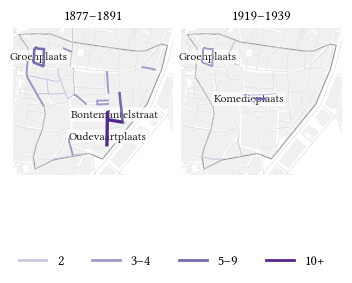

In [40]:
# ── groepen en instellingen ───────────────────────────────────────────────
UITBUNDIG = ["yelling", "arguing"]     # zoals in Afbeelding 8
PERIODEN = {"1877–1891": (1877, 1891), "1919–1939": (1919, 1939)}

KLASSEN = [2, 3, 5, 10, 10_000]
LABELS = ["2", "3–4", "5–9", "10+"]
KLEUREN = ["#CBC9E2", "#9E9AC8", "#756BB1", "#54278F"]
LABELS_PER_PERIODE = {
    "1877–1891": {
        "OUDEVAARTPLAATS": (0, -60),
        "BONTEMANTELSTRAAT": (0, 50),
        "GROENPLAATS": (0, 0),
    },
    "1919–1939": {
        "KOMEDIEPLAATS": (0, 0),
        "GROENPLAATS": (0, 0),
    },
}                          

# ── lagen ─────────────────────────────────────────────────────────────────
straten["naam"] = straten["LINK_GIS"].str.strip().str.upper()
wijk3 = wijken[wijken["SectionNr"].astype(str).str.strip() == "3"]

minx, miny, maxx, maxy = wijk3.total_bounds
marge = 0.04 * max(maxx - minx, maxy - miny)

def per_straat(a, b, kolommen):
    sub = df_gb[(df_gb["year"].between(a, b)) & (df_gb["E_LOC_gis1898"] != "unknown")]
    return sub.groupby("E_LOC_gis1898")[kolommen].sum().sum(axis=1).rename("n")

# ── kaart ─────────────────────────────────────────────────────────────────
fig, axen = plt.subplots(1, 2, figsize=(TEKSTBREEDTE, 3.8))

for ax, (titel, (a, b)) in zip(axen, PERIODEN.items()):
    tel = per_straat(a, b, UITBUNDIG)
    laag = straten.merge(tel, left_on="naam", right_index=True, how="left")

    bebouwing.plot(ax=ax, color="#F0F0F0", edgecolor="none", zorder=1)
    wijk3.boundary.plot(ax=ax, color=STEENGRIJS, lw=0.8, zorder=2)
    laag[laag["n"].isna() | (laag["n"] < KLASSEN[0])].plot(
        ax=ax, color="#D9D9D9", lw=0.4, zorder=3)

    for i in range(len(KLASSEN) - 1):
        sel = laag[(laag["n"] >= KLASSEN[i]) & (laag["n"] < KLASSEN[i + 1])]
        if len(sel):
            sel.plot(ax=ax, color=KLEUREN[i], lw=0.9 + i * 0.5, zorder=4 + i)

    for naam, (dx, dy) in LABELS_PER_PERIODE[titel].items():
        g = laag[laag["naam"] == naam]
        if not len(g):
            print(f"niet gevonden in laag: {naam}")
            continue
        p = g.geometry.union_all().centroid
        ax.annotate(naam.title(), (p.x + dx, p.y + dy), fontsize=CORPS_KLEIN, color="#222",
                    ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white",
                              ec="none", alpha=0.8))

    ax.set_title(titel, fontsize=CORPS)
    ax.set_axis_off()
    ax.set_xlim(minx - marge, maxx + marge)
    ax.set_ylim(miny - marge, maxy + marge)

handles = [Line2D([], [], color=k, lw=2, label=l) for k, l in zip(KLEUREN, LABELS)]
fig.legend(handles=handles, frameon=False, fontsize=CORPS, ncol=4,
           loc="lower center", bbox_to_anchor=(0.5, 0.06))
fig.subplots_adjust(bottom=0.14, wspace=0.05, top=0.92)

#bewaar(fig, "4.11_conflict_kaart")

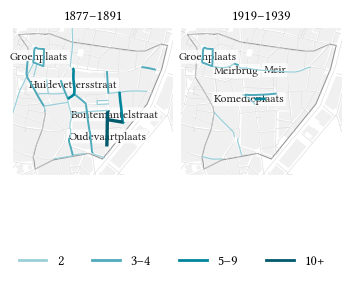

In [41]:
# ── groepen en instellingen ───────────────────────────────────────────────
UITBUNDIG = ["yelling", "singing"]     # zoals in Afbeelding 8
PERIODEN = {"1877–1891": (1877, 1891), "1919–1939": (1919, 1939)}

KLASSEN = [2, 3, 5, 10, 10_000]
LABELS = ["2", "3–4", "5–9", "10+"]
KLEUREN = ["#9ACFD9", "#4FAABA", "#00859B", "#005A6B"]
LABELS_PER_PERIODE = {
    "1877–1891": {
        "OUDEVAARTPLAATS": (0, -60),
        "BONTEMANTELSTRAAT": (0, 50),
        "GROENPLAATS": (0, 0),
        "HUIDEVETTERSSTRAAT": (0, 0)
    },
    "1919–1939": {
        "MEIR": (0, 0),
        "MEIRBRUG": (0, -50),
        "KOMEDIEPLAATS": (0, 0),
        "GROENPLAATS": (0, 0),
    },
}                          

# ── lagen ─────────────────────────────────────────────────────────────────
straten["naam"] = straten["LINK_GIS"].str.strip().str.upper()
wijk3 = wijken[wijken["SectionNr"].astype(str).str.strip() == "3"]

minx, miny, maxx, maxy = wijk3.total_bounds
marge = 0.04 * max(maxx - minx, maxy - miny)

def per_straat(a, b, kolommen):
    sub = df_gb[(df_gb["year"].between(a, b)) & (df_gb["E_LOC_gis1898"] != "unknown")]
    return sub.groupby("E_LOC_gis1898")[kolommen].sum().sum(axis=1).rename("n")

# ── kaart ─────────────────────────────────────────────────────────────────
fig, axen = plt.subplots(1, 2, figsize=(TEKSTBREEDTE, 3.8))

for ax, (titel, (a, b)) in zip(axen, PERIODEN.items()):
    tel = per_straat(a, b, UITBUNDIG)
    laag = straten.merge(tel, left_on="naam", right_index=True, how="left")

    bebouwing.plot(ax=ax, color="#F0F0F0", edgecolor="none", zorder=1)
    wijk3.boundary.plot(ax=ax, color=STEENGRIJS, lw=0.8, zorder=2)
    laag[laag["n"].isna() | (laag["n"] < KLASSEN[0])].plot(
        ax=ax, color="#D9D9D9", lw=0.4, zorder=3)

    for i in range(len(KLASSEN) - 1):
        sel = laag[(laag["n"] >= KLASSEN[i]) & (laag["n"] < KLASSEN[i + 1])]
        if len(sel):
            sel.plot(ax=ax, color=KLEUREN[i], lw=0.9 + i * 0.5, zorder=4 + i)

    for naam, (dx, dy) in LABELS_PER_PERIODE[titel].items():
        g = laag[laag["naam"] == naam]
        if not len(g):
            print(f"niet gevonden in laag: {naam}")
            continue
        p = g.geometry.union_all().centroid
        ax.annotate(naam.title(), (p.x + dx, p.y + dy), fontsize=CORPS_KLEIN, color="#222",
                    ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white",
                              ec="none", alpha=0.8))

    ax.set_title(titel, fontsize=CORPS)
    ax.set_axis_off()
    ax.set_xlim(minx - marge, maxx + marge)
    ax.set_ylim(miny - marge, maxy + marge)

handles = [Line2D([], [], color=k, lw=2, label=l) for k, l in zip(KLEUREN, LABELS)]
fig.legend(handles=handles, frameon=False, fontsize=CORPS, ncol=4,
           loc="lower center", bbox_to_anchor=(0.5, 0.06))
fig.subplots_adjust(bottom=0.14, wspace=0.05, top=0.92)

#bewaar(fig, "4.12_uitbundigheid_kaart")

In [42]:
def schaalbalk(ax, lengte=200):
    xa, xb = ax.get_xlim(); ya, yb = ax.get_ylim()
    x0 = xa + 0.58 * (xb - xa)
    y0 = ya + 0.07 * (yb - ya)
    h = 0.008 * (yb - ya)
    ax.add_patch(Rectangle((x0, y0), lengte, h, facecolor="#222", zorder=25))
    ax.text(x0 + lengte / 2, y0 + 1.6 * h, f"{lengte} m", ha="center",
            va="bottom", fontsize=CORPS_KLEIN, color="#222", zorder=25)

def noordpijl(ax):
    xa, xb = ax.get_xlim(); ya, yb = ax.get_ylim()
    x = xa + 0.92 * (xb - xa)
    y = ya + 0.07 * (yb - ya)
    lengte = 0.09 * (yb - ya)
    ax.annotate("", xy=(x, y + lengte), xytext=(x, y), zorder=25,
                arrowprops=dict(arrowstyle="-|>", color="#222", lw=1.1,
                                mutation_scale=11))
    ax.text(x, y + lengte + 0.012 * (yb - ya), "N", ha="center", va="bottom",
            fontsize=CORPS_KLEIN, color="#222", zorder=25)

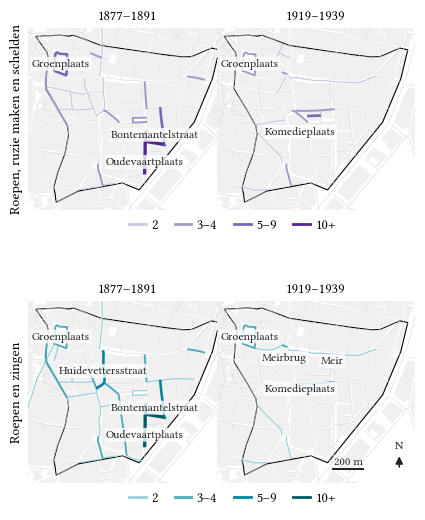

In [43]:
# ── instellingen ──────────────────────────────────────────────────────────
PERIODEN = {"1877–1891": (1877, 1891), "1919–1939": (1919, 1939)}
KLASSEN = [2, 3, 5, 10, 10_000]
LABELS = ["2", "3–4", "5–9", "10+"]

RIJEN = [
    {"kolommen": ["yelling", "arguing", "scolding"],
     "kleuren": ["#CBC9E2", "#9E9AC8", "#756BB1", "#54278F"],
     "titel": "Roepen, ruzie maken en schelden",
     "labels": {
         "1877–1891": {"OUDEVAARTPLAATS": (0, -60),
                       "BONTEMANTELSTRAAT": (0, 50),
                       "GROENPLAATS": (0, 0)},
         "1919–1939": {"KOMEDIEPLAATS": (0, -100), "GROENPLAATS": (0, 0)},
     }},
    {"kolommen": ["yelling", "singing"],
     "kleuren": ["#9ACFD9", "#4FAABA", "#00859B", "#005A6B"],
     "titel": "Roepen en zingen",
     "labels": {
         "1877–1891": {"OUDEVAARTPLAATS": (0, -60),
                       "BONTEMANTELSTRAAT": (0, 50),
                       "GROENPLAATS": (0, 0),
                       "HUIDEVETTERSSTRAAT": (0, 0)},
         "1919–1939": {"MEIR": (0, -50), "MEIRBRUG": (0, -75),
                       "KOMEDIEPLAATS": (0, 0), "GROENPLAATS": (0, 0)},
     }},
]

# ── lagen ─────────────────────────────────────────────────────────────────
straten["naam"] = straten["LINK_GIS"].str.strip().str.upper()
wijk3 = wijken[wijken["SectionNr"].astype(str).str.strip() == "3"]
minx, miny, maxx, maxy = wijk3.total_bounds
marge = 0.04 * max(maxx - minx, maxy - miny)

def per_straat(a, b, kolommen):
    sub = df_gb[(df_gb["year"].between(a, b)) & (df_gb["E_LOC_gis1898"] != "unknown")]
    return sub.groupby("E_LOC_gis1898")[kolommen].sum().sum(axis=1).rename("n")

# ── kaart ─────────────────────────────────────────────────────────────────
fig, axen = plt.subplots(2, 2, figsize=(TEKSTBREEDTE, 5.6))

for r, spec in enumerate(RIJEN):
    for c, (titel, (a, b)) in enumerate(PERIODEN.items()):
        ax = axen[r, c]
        tel = per_straat(a, b, spec["kolommen"])
        laag = straten.merge(tel, left_on="naam", right_index=True, how="left")

        bebouwing.plot(ax=ax, color="#F0F0F0", edgecolor="none", zorder=1)
        wijk3.boundary.plot(ax=ax, color="black", lw=0.8, zorder=2)
        laag[laag["n"].isna() | (laag["n"] < KLASSEN[0])].plot(
            ax=ax, color="#D9D9D9", lw=0.4, zorder=3)

        for i in range(len(KLASSEN) - 1):
            sel = laag[(laag["n"] >= KLASSEN[i]) & (laag["n"] < KLASSEN[i + 1])]
            if len(sel):
                sel.plot(ax=ax, color=spec["kleuren"][i],
                         lw=0.9 + i * 0.5, zorder=4 + i)

        for naam, (dx, dy) in spec["labels"][titel].items():
            g = laag[laag["naam"] == naam]
            if not len(g):
                print(f"niet gevonden in laag: {naam}")
                continue
            p = g.geometry.union_all().centroid
            ax.annotate(naam.title(), (p.x + dx, p.y + dy), fontsize=CORPS_KLEIN,
                        color="#222", ha="center", va="center", zorder=20,
                        bbox=dict(boxstyle="round,pad=0.12", fc="white",
                                  ec="none", alpha=0.8))

        ax.set_title(titel, fontsize=CORPS)
        ax.set_axis_off()
        ax.set_xlim(minx - marge, maxx + marge)
        ax.set_ylim(miny - marge, maxy + marge)

        if r == 1 and c == 1:
            schaalbalk(ax, lengte=200)
            noordpijl(ax)

    # rijtitel links, legende onder de rij
    axen[r, 0].text(-0.06, 0.5, spec["titel"], transform=axen[r, 0].transAxes,
                    rotation=90, ha="center", va="center", fontsize=CORPS)

    handles = [Line2D([], [], color=k, lw=2, label=l)
               for k, l in zip(spec["kleuren"], LABELS)]
    axen[r, 0].legend(handles=handles, frameon=False, fontsize=CORPS, ncol=4,
                      loc="upper center", bbox_to_anchor=(1.03, 0.02),
                      columnspacing=1.2, handlelength=1.2, handletextpad=0.4)

fig.subplots_adjust(wspace=-0.05, hspace=0.18, left=0.06, top=0.95, bottom=0.05)
bewaar(fig, "8.13_klankruimtes_kaart")

In [44]:
for spec in RIJEN:
    print(f"\n{spec['titel']}")
    for titel, (a, b) in PERIODEN.items():
        sub = df_gb[(df_gb["year"].between(a, b))
                    & (df_gb["E_LOC_gis1898"] != "unknown")]
        n_geb = int(sub[spec["kolommen"]].max(axis=1).eq(1).sum())
        tel = per_straat(a, b, spec["kolommen"])
        print(f"  {titel}: {n_geb} gebeurtenissen | "
              f"{int(tel.sum())} registraties | "
              f"{(tel >= KLASSEN[0]).sum()} straten getoond "
              f"(van {(tel >= 1).sum()} met minstens één)")


Roepen, ruzie maken en schelden
  1877–1891: 189 gebeurtenissen | 185 registraties | 35 straten getoond (van 76 met minstens één)
  1919–1939: 64 gebeurtenissen | 64 registraties | 16 straten getoond (van 35 met minstens één)

Roepen en zingen
  1877–1891: 206 gebeurtenissen | 205 registraties | 43 straten getoond (van 81 met minstens één)
  1919–1939: 65 gebeurtenissen | 58 registraties | 14 straten getoond (van 30 met minstens één)
